In [16]:
import pandas as pd
import numpy as np

In [17]:
df = pd.read_csv('../dataset/dataset_bai03.csv')
df

,dạsymboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [21]:
df.replace(to_replace='?', value=np.nan, inplace=True)
df.dropna(subset=['price', 'horsepower'], inplace=True)

In [22]:
df['price'] = df['price'].astype(float)
df['horsepower'] = df['horsepower'].astype(float)

## 1. Cột price

In [23]:
df['price'].mean(), df['price'].median()

(np.float64(13243.43216080402), np.float64(10345.0))

In [24]:
df['price'].mode()

0      5572.0
1      6229.0
2      6692.0
3      7295.0
4      7609.0
5      7775.0
6      7898.0
7      7957.0
8      8495.0
9      8845.0
10     8921.0
11     9279.0
12    13499.0
13    16500.0
14    18150.0
Name: price, dtype: float64

In [25]:
df['price'].skew()

np.float64(1.793653855836438)

<Axes: ylabel='Density'>

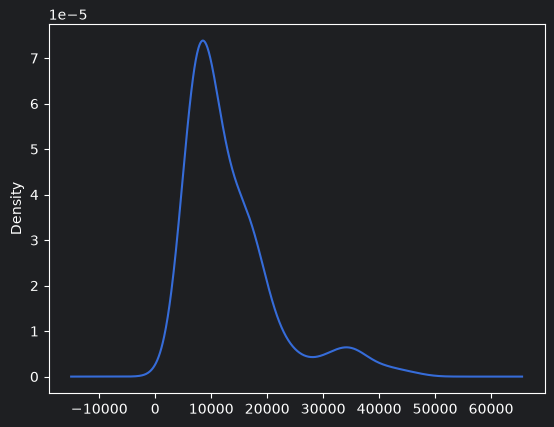

In [26]:
df['price'].plot(kind='kde')

skew = 1.81 > 0 => lệch phải, đuôi kéo dài về phía giá cao.

In [27]:
df['price'].kurt()

np.float64(3.162492496838782)

<Axes: >

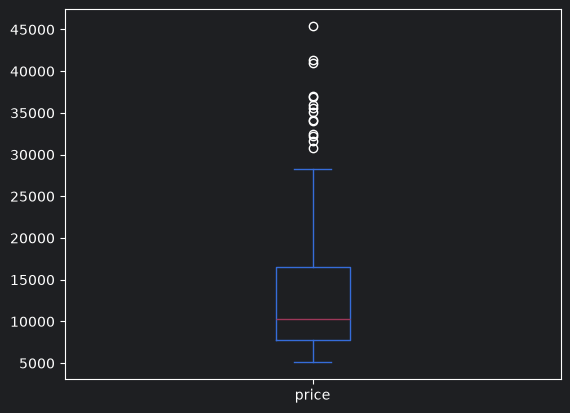

In [29]:
df['price'].plot(kind='box')

In [32]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
Min = Q1 - 1.5 * IQR
Max = Q3 + 1.5 * IQR
Q1, Q3, IQR, Min, Max

(np.float64(7775.0),
 np.float64(16501.5),
 np.float64(8726.5),
 np.float64(-5314.75),
 np.float64(29591.25))

In [33]:
df[(df['price'] < Min) | (df['price'] > Max)]

,dạsymboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
15,0,NaN,bmw,gas,std,four,sedan,rwd,front,103.5,...,209,mpfi,3.62,3.39,8.0,182.0,5400,16,22,30760.0
16,0,NaN,bmw,gas,std,two,sedan,rwd,front,103.5,...,209,mpfi,3.62,3.39,8.0,182.0,5400,16,22,41315.0
17,0,NaN,bmw,gas,std,four,sedan,rwd,front,110.0,...,209,mpfi,3.62,3.39,8.0,182.0,5400,15,20,36880.0
47,0,145,jaguar,gas,std,four,sedan,rwd,front,113.0,...,258,mpfi,3.63,4.17,8.1,176.0,4750,15,19,32250.0
48,0,NaN,jaguar,gas,std,four,sedan,rwd,front,113.0,...,258,mpfi,3.63,4.17,8.1,176.0,4750,15,19,35550.0
49,0,NaN,jaguar,gas,std,two,sedan,rwd,front,102.0,...,326,mpfi,3.54,2.76,11.5,262.0,5000,13,17,36000.0
70,-1,93,mercedes-benz,diesel,turbo,four,sedan,rwd,front,115.6,...,183,idi,3.58,3.64,21.5,123.0,4350,22,25,31600.0
71,-1,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,115.6,...,234,mpfi,3.46,3.10,8.3,155.0,4750,16,18,34184.0
72,3,142,mercedes-benz,gas,std,two,convertible,rwd,front,96.6,...,234,mpfi,3.46,3.10,8.3,155.0,4750,16,18,35056.0
73,0,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,...,308,mpfi,3.80,3.35,8.0,184.0,4500,14,16,40960.0


## 2. Cột length

In [34]:
df['length'].mean(), df['length'].median()

(np.float64(174.151256281407), np.float64(173.2))

In [35]:
df['length'].mode()

0    157.3
Name: length, dtype: float64

Mode (0.756) < Median (0.832) < Mean (0.837) => lệch phải nhẹ.

In [36]:
df['length'].skew()

np.float64(0.16523679664100577)

<Axes: ylabel='Density'>

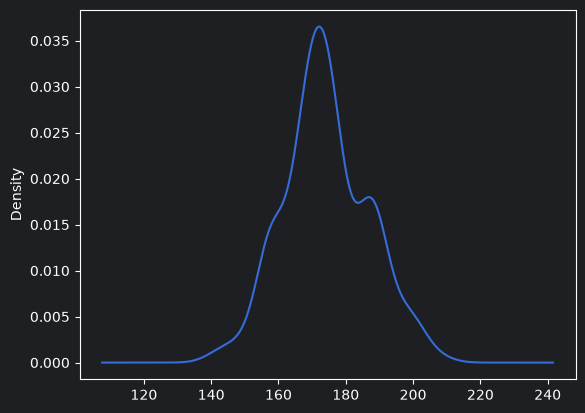

In [37]:
df['length'].plot(kind='kde')

skew = 0.154 gần bằng 0 => dữ liệu gần như đối xứng.

In [38]:
df['length'].kurt()

np.float64(-0.08079561481793984)

<Axes: >

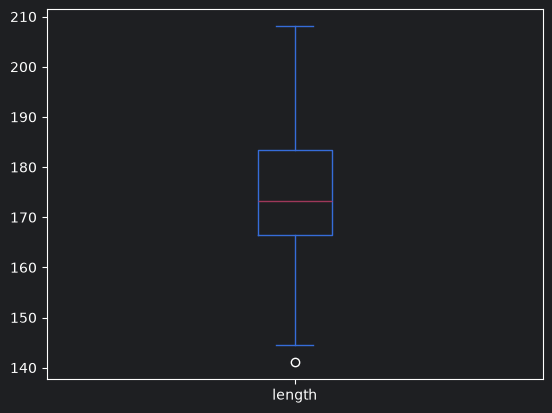

In [39]:
df['length'].plot(kind='box')

In [40]:
Q1 = df['length'].quantile(0.25)
Q3 = df['length'].quantile(0.75)
IQR = Q3 - Q1
Min = Q1 - 1.5 * IQR
Max = Q3 + 1.5 * IQR
Q1, Q3, IQR, Min, Max

(np.float64(166.55),
 np.float64(183.5),
 np.float64(16.94999999999999),
 np.float64(141.12500000000003),
 np.float64(208.92499999999998))

In [41]:
df[(df['length'] < Min) | (df['length'] > Max)]

,dạsymboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
18,2,121,chevrolet,gas,std,two,hatchback,fwd,front,88.4,...,61,2bbl,2.91,3.03,9.5,48.0,5100,47,53,5151.0


## 3. Cột horsepower

In [42]:
df['horsepower'].mean(), df['horsepower'].median()

(np.float64(103.39698492462311), np.float64(95.0))

In [43]:
df['horsepower'].mode()

0    68.0
Name: horsepower, dtype: float64

Có 1 mode: Mode (68) < Median (95) < Mean (103) => lệch phải.

In [44]:
df['horsepower'].skew()

np.float64(1.141584284163145)

<Axes: ylabel='Density'>

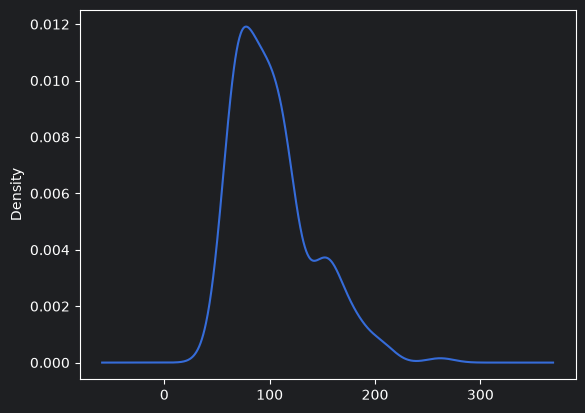

In [45]:
df['horsepower'].plot(kind='kde')

skew = 1.147 > 0 => lệch phải.

In [46]:
df['horsepower'].kurt()

np.float64(1.278670760030777)

<Axes: >

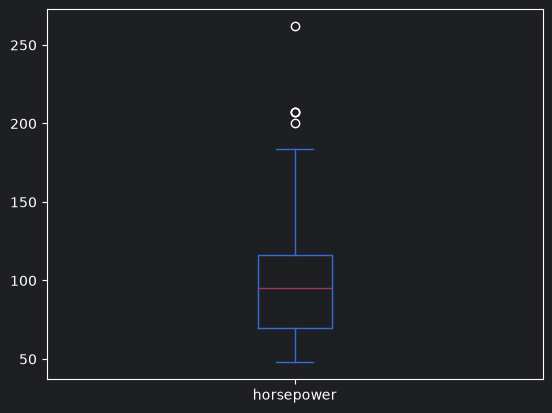

In [47]:
df['horsepower'].plot(kind='box')

In [48]:
Q1 = df['horsepower'].quantile(0.25)
Q3 = df['horsepower'].quantile(0.75)
IQR = Q3 - Q1
Min = Q1 - 1.5 * IQR
Max = Q3 + 1.5 * IQR
Q1, Q3, IQR, Min, Max

(np.float64(70.0),
 np.float64(116.0),
 np.float64(46.0),
 np.float64(1.0),
 np.float64(185.0))

In [50]:
df[(df['horsepower'] < Min) | (df['horsepower'] > Max)]

,dạsymboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
49,0,NaN,jaguar,gas,std,two,sedan,rwd,front,102.0,...,326,mpfi,3.54,2.76,11.5,262.0,5000,13,17,36000.0
105,3,194,nissan,gas,turbo,two,hatchback,rwd,front,91.3,...,181,mpfi,3.43,3.27,7.8,200.0,5200,17,23,19699.0
126,3,NaN,porsche,gas,std,two,hardtop,rwd,rear,89.5,...,194,mpfi,3.74,2.90,9.5,207.0,5900,17,25,32528.0
127,3,NaN,porsche,gas,std,two,hardtop,rwd,rear,89.5,...,194,mpfi,3.74,2.90,9.5,207.0,5900,17,25,34028.0
128,3,NaN,porsche,gas,std,two,convertible,rwd,rear,89.5,...,194,mpfi,3.74,2.90,9.5,207.0,5900,17,25,37028.0


## 4. Cột engine-size

In [51]:
df['engine-size'].mean(), df['engine-size'].median()

(np.float64(126.82412060301507), np.float64(119.0))

In [53]:
df['engine-size'].mode()

0     92
1    122
Name: engine-size, dtype: int64

 Mean (126.9) > Median (120) => lệch phải.

In [54]:
df['engine-size'].skew()

np.float64(1.9735956839887074)

<Axes: ylabel='Density'>

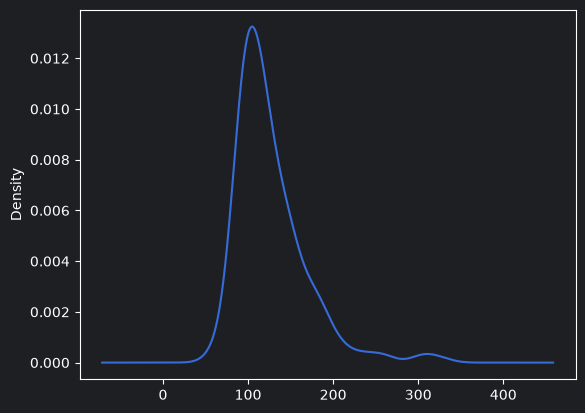

In [55]:
df['engine-size'].plot(kind='kde')

skew = 1.979 => lệch phải mạnh nhất trong các cột đang xét.

In [56]:
df['engine-size'].kurt()

np.float64(5.426683661534259)

<Axes: >

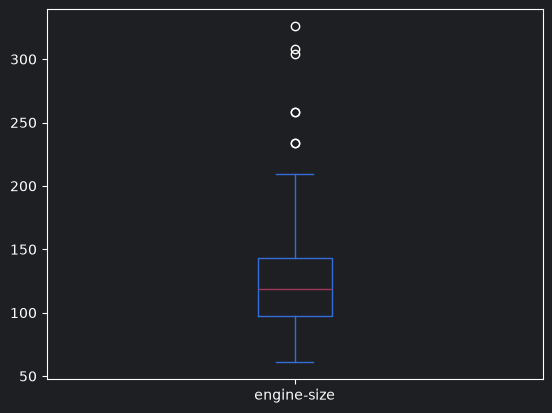

In [57]:
df['engine-size'].plot(kind='box')

In [58]:
Q1 = df['engine-size'].quantile(0.25)
Q3 = df['engine-size'].quantile(0.75)
IQR = Q3 - Q1
Min = Q1 - 1.5 * IQR
Max = Q3 + 1.5 * IQR
Q1, Q3, IQR, Min, Max

(np.float64(97.5),
 np.float64(143.0),
 np.float64(45.5),
 np.float64(29.25),
 np.float64(211.25))

In [59]:
df[(df['engine-size'] < Min) | (df['engine-size'] > Max)]

,dạsymboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
47,0,145,jaguar,gas,std,four,sedan,rwd,front,113.0,...,258,mpfi,3.63,4.17,8.1,176.0,4750,15,19,32250.0
48,0,NaN,jaguar,gas,std,four,sedan,rwd,front,113.0,...,258,mpfi,3.63,4.17,8.1,176.0,4750,15,19,35550.0
49,0,NaN,jaguar,gas,std,two,sedan,rwd,front,102.0,...,326,mpfi,3.54,2.76,11.5,262.0,5000,13,17,36000.0
71,-1,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,115.6,...,234,mpfi,3.46,3.10,8.3,155.0,4750,16,18,34184.0
72,3,142,mercedes-benz,gas,std,two,convertible,rwd,front,96.6,...,234,mpfi,3.46,3.10,8.3,155.0,4750,16,18,35056.0
73,0,NaN,mercedes-benz,gas,std,four,sedan,rwd,front,120.9,...,308,mpfi,3.80,3.35,8.0,184.0,4500,14,16,40960.0
74,1,NaN,mercedes-benz,gas,std,two,hardtop,rwd,front,112.0,...,304,mpfi,3.80,3.35,8.0,184.0,4500,14,16,45400.0
